# Ionização e pH: a conta exata e a aproximada
### Funções inorgânicas — ácidos

**Objetivo:** Montar a tabela de equilíbrio de ionização, obter $[\mathrm{H_3O^+}]$ pela aproximação $\sqrt{K_a c}$ e pela fórmula exata, e ver quando cada uma é válida.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Quando um ácido é dissolvido em água, o equilíbrio de ionização depende de **duas** coisas: da força do ácido ($K_a$) e da concentração. Dois produtos iônicos que aparecem em toda conta:

$$
\boxed{K_w = [\mathrm{H_3O^+}][\mathrm{OH^-}] = 1{,}0\times10^{-14}\ \text{a }25\,^\circ\mathrm{C}}
$$

$$
\boxed{\mathrm{pH} + \mathrm{pOH} = 14}
$$

Para um ácido fraco monoprótico com concentração $c$, monta-se a tabela de equilíbrio (ICE):

| | $\mathrm{HA}$ | $\mathrm{H_3O^+}$ | $\mathrm{A^-}$ |
|---|---|---|---|
| inicial | $c$ | 0 | 0 |
| variação | $-x$ | $+x$ | $+x$ |
| equilíbrio | $c-x$ | $x$ | $x$ |

$$
K_a = \frac{x^2}{c-x}\ \xrightarrow[\ x \ll c\ ]{}\ x \approx \sqrt{K_a\,c}
$$

A tabela mostra também **quando a aproximação vale**: só se $x$ for pequeno comparado a $c$ (regra prática: ionização menor que 5%). Para ácido muito fraco ou muito diluído, é preciso resolver a equação do 2º grau — o notebook faz as duas contas e compara.

## 2. Exemplo resolvido passo a passo

Ácido acético a $c = 0{,}010\ \mathrm{mol/L}$, com $K_a = 1{,}8\times10^{-5}$.

**Passo 1 — aproximação.**

$$
x \approx \sqrt{1{,}8\times10^{-5}\cdot 0{,}010} = \sqrt{1{,}8\times10^{-7}} = 4{,}24\times10^{-4}\ \mathrm{mol/L}
$$

$$
\mathrm{pH} = -\log_{10}(4{,}24\times10^{-4}) = \boxed{3{,}37}
$$

**Passo 2 — conferindo pela fórmula exata (Bhaskara).**

$$
x^2 + K_a x - K_a c = 0
\ \Rightarrow\
x = \frac{-K_a + \sqrt{K_a^2 + 4K_a c}}{2} = 4{,}16\times10^{-4}\ \mathrm{mol/L}
$$

$$
\mathrm{pH} = 3{,}38
$$

**Passo 3 — o quanto a aproximação errou.**

$$
\text{erro relativo} = \frac{|4{,}24 - 4{,}16|}{4{,}16} = 1{,}9\%
$$

Pequeno aqui, mas cresce rápido quando a solução é diluída ou o ácido é mais forte — é o que o gráfico da seção 4 mostra.

## 3. Conferindo o cálculo com Python

In [2]:
# @title pH: aproximação x fórmula exata
import math

KW = 1.0e-14

def h_aproximado(c, ka):
    """Aproximação clássica, válida quando a ionização é pequena."""
    return math.sqrt(ka * c)

def h_exato(c, ka):
    """Resolve x^2 + Ka*x - Ka*c = 0 e devolve a raiz positiva."""
    return (-ka + math.sqrt(ka ** 2 + 4 * ka * c)) / 2

def ph(h):
    return -math.log10(h)

C, KA = 0.010, 1.8e-5
h1, h2 = h_aproximado(C, KA), h_exato(C, KA)

print(f"Concentração:            {C:.4f} mol/L")
print(f"[H+] aproximado:         {h1:.3e} mol/L  ->  pH {ph(h1):.2f}")
print(f"[H+] exato:              {h2:.3e} mol/L  ->  pH {ph(h2):.2f}")
print(f"Erro da aproximação:     {100 * abs(h1 - h2) / h2:.1f} %")
print(f"[OH-] (de Kw):           {KW / h2:.2e} mol/L")
print(f"pH + pOH:                {ph(h2) + (-math.log10(KW / h2)):.2f}")

Concentração:            0.0100 mol/L
[H+] aproximado:         4.243e-04 mol/L  ->  pH 3.37
[H+] exato:              4.154e-04 mol/L  ->  pH 3.38
Erro da aproximação:     2.1 %
[OH-] (de Kw):           2.41e-11 mol/L
pH + pOH:                14.00


## 4. Visualização

### 4.1 O íon hidrônio em 3D — arraste para girar

O $\mathrm{H_3O^+}$ tem geometria **piramidal trigonal**: o oxigênio fica no topo e os três hidrogênios formam a base. Gire a figura e observe que a molécula não é plana (o ângulo H–O–H é de aproximadamente 113°).

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[OH3+]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 O ânion acetato em 3D

O acetato $\mathrm{CH_3COO^-}$ é a base conjugada do ácido acético. Repare que **as duas ligações C–O ficam iguais**, com a carga negativa repartida entre os dois oxigênios (ressonância) — é por isso que o ânion é estabilizado.

In [4]:
molecula_3d("CC(=O)[O-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

No 2D, compare o ácido ($\mathrm{C=O}$ dupla + $\mathrm{C-O-H}$ simples) com o ânion (apenas $\mathrm{C-O^-}$). A diferença de um próton é o que define o par conjugado.

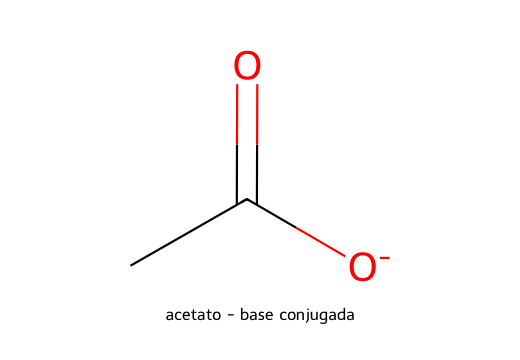

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("CC(=O)O", legenda="acido acetico - doador de H+")
estrutura_2d("CC(=O)[O-]", legenda="acetato - base conjugada")

### 4.4 A escala de pH

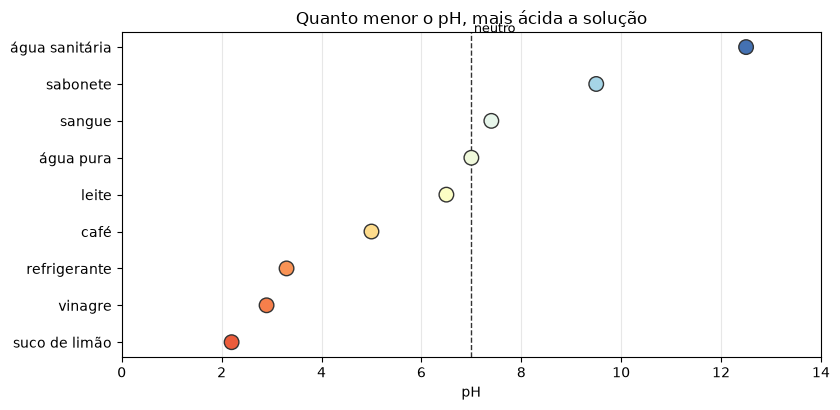

In [6]:
# @title Escala de pH com exemplos
import numpy as np
import matplotlib.pyplot as plt

amostras = [
    ("suco de limão", 2.2), ("vinagre", 2.9), ("refrigerante", 3.3),
    ("café", 5.0), ("leite", 6.5), ("água pura", 7.0),
    ("sangue", 7.4), ("sabonete", 9.5), ("água sanitária", 12.5),
]
nomes = [nome for nome, _ in amostras]
valores = [valor for _, valor in amostras]

plt.figure(figsize=(8.5, 4.2))
cores = plt.get_cmap("RdYlBu")(np.interp(valores, [0, 7, 14], [0, 0.55, 1]))
plt.scatter(valores, range(len(valores)), s=110, c=cores, edgecolor="#333", zorder=3)
plt.yticks(range(len(valores)), nomes)
plt.axvline(7, color="#333", linestyle="--", linewidth=1)
plt.text(7.05, len(valores) - 0.6, "neutro", fontsize=9)
plt.xlim(0, 14)
plt.xlabel("pH")
plt.title("Quanto menor o pH, mais ácida a solução")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.5 Onde a aproximação $\sqrt{K_a c}$ começa a errar

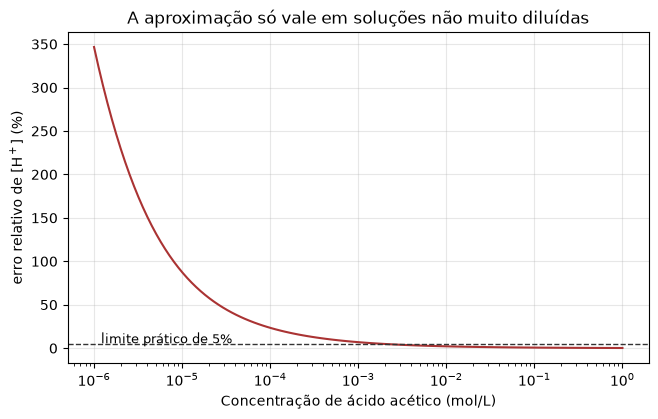

In [7]:
# @title Erro da aproximação em função da concentração
concentracoes = np.logspace(-6, 0, 120)
erro = 100 * abs(np.sqrt(KA * concentracoes) - [h_exato(c, KA) for c in concentracoes]) \
       / np.array([h_exato(c, KA) for c in concentracoes])

plt.figure(figsize=(7.5, 4.3))
plt.plot(concentracoes, erro, color="#a33")
plt.axhline(5, color="#333", linestyle="--", linewidth=1)
plt.text(1.2e-6, 5.6, "limite prático de 5%", fontsize=9)
plt.xscale("log")
plt.xlabel("Concentração de ácido acético (mol/L)")
plt.ylabel("erro relativo de $[\\mathrm{H^+}]$ (%)")
plt.title("A aproximação só vale em soluções não muito diluídas")
plt.grid(alpha=0.3)
plt.show()

## 5. Como interpretar o resultado

- A conta aproximada acertou o pH até a segunda casa no exemplo; o erro aparece com força abaixo de $\sim10^{-4}\ \mathrm{mol/L}$, quando o ácido passa a ionizar uma fração grande do total.
- $\mathrm{pH} + \mathrm{pOH} = 14$ é uma conferência rápida: achou $[\mathrm{H^+}]$, o $[\mathrm{OH^-}]$ já está determinado.
- No 3D, o $\mathrm{H_3O^+}$ piramidal mostra que o próton não anda solto: ele se liga à água. Escrever $\mathrm{H^+}$ é uma abreviação.
- A carga do acetato espalhada nos dois oxigênios (ressonância) explica por que o ácido acético é mais forte que um álcool — a base conjugada é estabilizada.

## 6. Exercício de fixação

Uma solução de amônia tem $K_b = 1{,}8\times10^{-5}$ e concentração $0{,}050\ \mathrm{mol/L}$. Calcule o pOH, o pH e $[\mathrm{H^+}]$.

Tente prever antes de executar a célula.

In [8]:
# @title Exercício
KB, C_EX = 1.8e-5, 0.050
oh_ex = math.sqrt(KB * C_EX)          # base fraca: mesma matemática
poh_ex = -math.log10(oh_ex)
ph_ex = 14 - poh_ex

print(f"[OH-] = {oh_ex:.2e} mol/L")
print(f"pOH   = {poh_ex:.2f}")
print(f"pH    = {ph_ex:.2f}")
print(f"[H+]  = {KW / oh_ex:.2e} mol/L")

[OH-] = 9.49e-04 mol/L
pOH   = 3.02
pH    = 10.98
[H+]  = 1.05e-11 mol/L


## 7. Resumo

- $K_w = 1{,}0\times10^{-14}$ e $\mathrm{pH} + \mathrm{pOH} = 14$ a 25 °C.
- Ácido fraco: $x \approx \sqrt{K_a c}$ **se** a ionização for pequena; senão use Bhaskara.
- $\mathrm{pH} = -\log[\mathrm{H^+}]$; $[\mathrm{OH^-}] = K_w / [\mathrm{H^+}]$.
- Ácido e base conjugada diferem por um próton; a carga se estabiliza por ressonância no ânion.
- Sempre confira se o resultado faz sentido na escala 0–14.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- SKOOG, D. *Fundamentos de Química Analítica*. Cengage.